# psfcal quickstart

Runs entirely on synthetic data (no FITS files needed) so you can execute
it top to bottom right after installing the package. In real use, `x`,
`y`, `y_err` come from a background-subtracted spectral chunk, and
`wave_order` / `theoretical_wavelengths` come from your wavelength
solution and line list (LFC comb modes, ThAr catalogue, ...).

```
pip install -e ".[plot]"
```

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import psfcal
from psfcal import plotting

rng = np.random.default_rng(42)
C_LIGHT_MPS = 299_792_458.0

## 1. Build a synthetic pixel-space chunk

A comb of emission lines, each individually smeared by a known (asymmetric) instrumental kernel, plus noise.

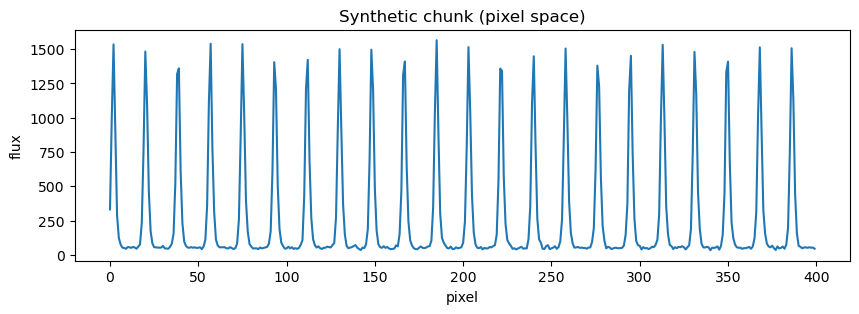

In [2]:
def make_kernel():
    dx = np.linspace(-8, 8, 4000)
    g1 = np.exp(-0.5 * (dx / 0.9) ** 2)
    g2 = 0.35 * np.exp(-0.5 * ((dx - 0.4) / 1.6) ** 2)
    y = g1 + g2
    y /= np.trapz(y, dx)
    centroid = np.trapz(dx * y, dx)
    dx = dx - centroid
    y /= np.trapz(y, dx)
    return dx, y

kx, ky = make_kernel()

n_pix = 400
x = np.arange(n_pix, dtype=float)
line_centres = np.arange(2, n_pix - 2, 18.3)

y_true = np.full(n_pix, 50.0)
for c in line_centres:
    y_true += 4000.0 * np.interp(x - c, kx, ky, left=0.0, right=0.0)

y_err = np.sqrt(np.abs(y_true) + 1.0)
y_obs = np.clip(y_true + rng.normal(0.0, y_err), 0.0, None)

plt.figure(figsize=(10, 3))
plt.plot(x, y_obs)
plt.xlabel("pixel"); plt.ylabel("flux"); plt.title("Synthetic chunk (pixel space)")
plt.show()

## 2. Item 1 — reconstruct the PSF in pixel space

`compute_psf_chunk_pixel(x, y, y_err, n_iterations=1, ...)`.

PSF centroid: -5.590801934424199 +/- 0.01671319827315736 pix


/Users/maddalenabugatti/Desktop/psfcal/src/psfcal/plotting.py:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


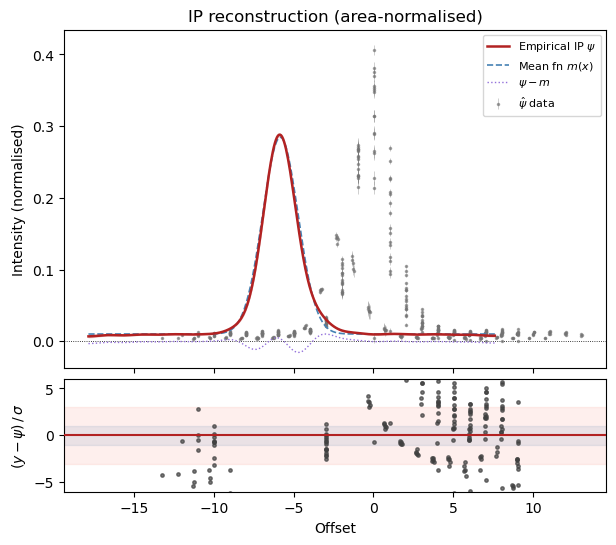

In [3]:
psf_pixel = psfcal.compute_psf_chunk_pixel(
    x, y_obs, y_err,
    n_iterations=1,
    n_psf_points=400,
)
print("PSF centroid:", psf_pixel["psf_centroid"], "+/-", psf_pixel["psf_centroid_err"], "pix")

plotting.plot_psf(psf_pixel)
plt.show()

## 3. Items 6 & 3 — forward-convolve, then deconvolve a chunk (pixel space)

Start from a sharp "true" spectrum, convolve it with the PSF we just reconstructed to simulate the instrument, then deconvolve it back out.

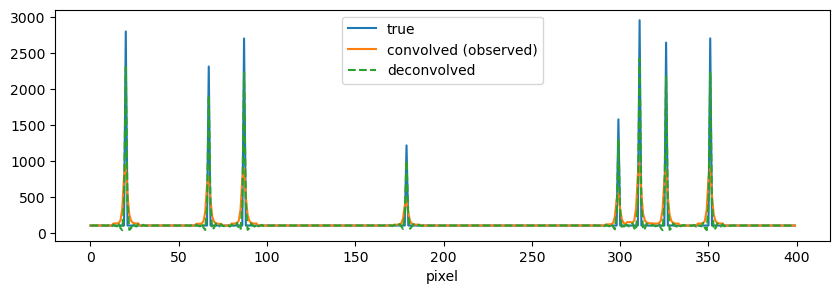

In [4]:
clean_spectrum = np.full(n_pix, 100.0)
spike_positions = rng.choice(np.arange(15, n_pix - 15), size=8, replace=False)
for p in spike_positions:
    clean_spectrum[p] += rng.uniform(1000, 3000)

observed = psfcal.convolve_chunk_pixel(
    clean_spectrum, psf_pixel["psf_x"], psf_pixel["psf_mean"], pixel_radius=7,
)
recovered = psfcal.deconvolve_chunk_pixel(
    observed, psf_pixel["psf_x"], psf_pixel["psf_mean"],
    pixel_radius=7, rl_iters=100, overlap_pix=10,
)

plt.figure(figsize=(10, 3))
plt.plot(x, clean_spectrum, label="true")
plt.plot(x, observed, label="convolved (observed)")
plt.plot(x, recovered, label="deconvolved", ls="--")
plt.legend(); plt.xlabel("pixel")
plt.show()

## 4. Item 2 — reconstruct the PSF in RV space

Given a wavelength solution and the theoretical wavelengths of the lines (e.g. LFC comb modes), `compute_psf_chunk_rv` anchors each line to its theoretical position instead of a fitted Gaussian centre.

theoretical lines matched: 22


/Users/maddalenabugatti/Desktop/psfcal/src/psfcal/plotting.py:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


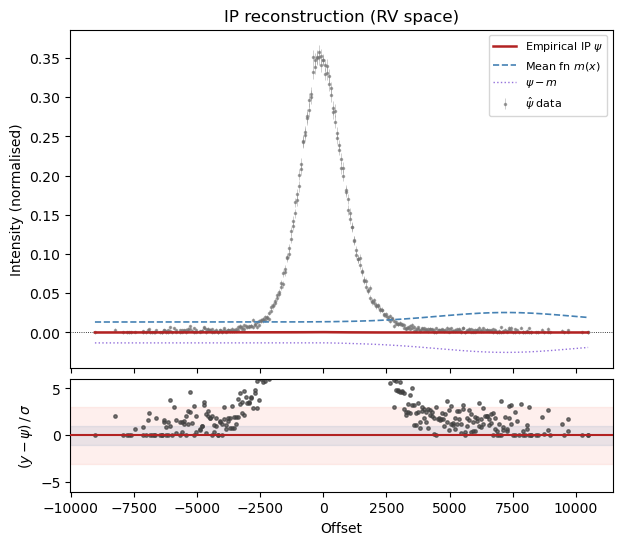

In [5]:
mps_per_pix = 800.0  # HARPS-like local dispersion, m/s/pixel
lam0 = 5000e-10  # metres
wave_order = lam0 + x * (lam0 * mps_per_pix / C_LIGHT_MPS)

theoretical_wavelengths = np.interp(line_centres, x, wave_order)

kv = kx * mps_per_pix  # same kernel, expressed on a velocity axis
y_rv_true = np.full(n_pix, 50.0)
for lam_theo in theoretical_wavelengths:
    dv = C_LIGHT_MPS * (wave_order - lam_theo) / lam_theo
    y_rv_true += 4000.0 * np.interp(dv, kv, ky, left=0.0, right=0.0)

y_rv_err = np.sqrt(np.abs(y_rv_true) + 1.0)
y_rv_obs = np.clip(y_rv_true + rng.normal(0.0, y_rv_err), 0.0, None)

psf_rv = psfcal.compute_psf_chunk_rv(
    x, y_rv_obs, y_rv_err, wave_order, theoretical_wavelengths,
    n_iterations=1, n_psf_points=300,
)
print("theoretical lines matched:", psf_rv["n_lines_used"])

plotting.plot_psf(psf_rv, title="IP reconstruction (RV space)")
plt.show()

## 5. Items 4 & 7 — convolve / deconvolve a chunk in RV space

Same idea as step 3, but the PSF lives on a velocity grid; `wave_chunk` (or a precomputed `mps_per_pix`) supplies the local dispersion needed to turn it into a pixel kernel.

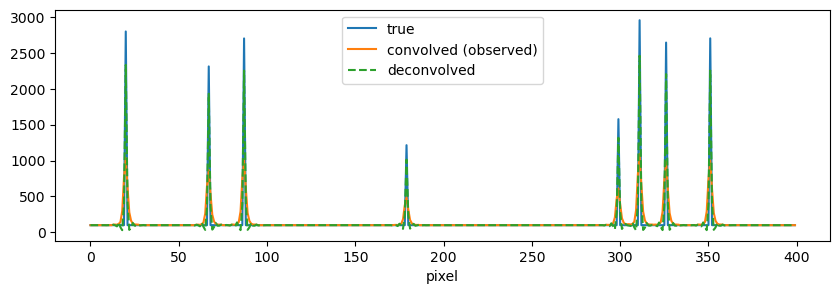

In [6]:
observed_rv = psfcal.convolve_chunk_rv(
    clean_spectrum, psf_rv["psf_x"], psf_rv["psf_mean"], wave_chunk=wave_order,
)
recovered_rv = psfcal.deconvolve_chunk_rv(
    observed_rv, psf_rv["psf_x"], psf_rv["psf_mean"], wave_chunk=wave_order,
    rl_iters=100, overlap_pix=10,
)

plt.figure(figsize=(10, 3))
plt.plot(x, clean_spectrum, label="true")
plt.plot(x, observed_rv, label="convolved (observed)")
plt.plot(x, recovered_rv, label="deconvolved", ls="--")
plt.legend(); plt.xlabel("pixel")
plt.show()

## 6. Item 5 — deconvolve a full order from per-chunk PSFs

`deconvolve_order` stitches per-chunk Richardson-Lucy deconvolutions together with overlap-add + a cosine taper across chunk boundaries. Here we reuse the same pixel-space PSF for every chunk for simplicity; in practice each chunk has its own PSF (e.g. one row per chunk out of `compute_psf_chunk_pixel`/`_rv`).

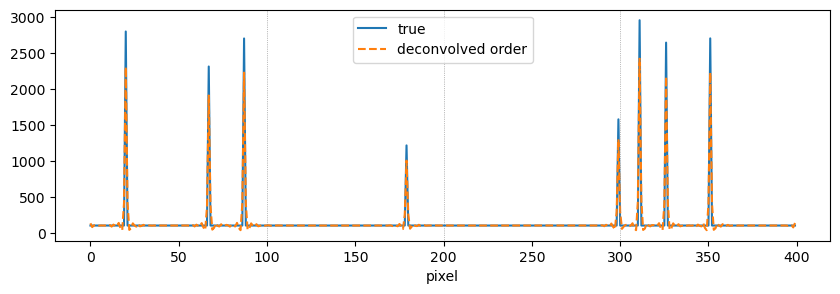

In [7]:
n_chunks = 4
edges = np.linspace(0, n_pix, n_chunks + 1).astype(int)
chunk_edges = np.stack([edges[:-1], edges[1:]], axis=1)

psi_cube = np.tile(psf_pixel["psf_mean"], (n_chunks, 1))
offsets_cube = np.tile(psf_pixel["psf_x"], (n_chunks, 1))

order_observed = psfcal.convolve_chunk_pixel(
    clean_spectrum, psf_pixel["psf_x"], psf_pixel["psf_mean"],
)
order_recovered = psfcal.deconvolve_order(
    order_observed, psi_cube, offsets_cube, chunk_edges,
    scale="pixel", rl_iters=100, pixel_radius=7, overlap_pix=12,
    continuum_normalize=False,
)

plt.figure(figsize=(10, 3))
plt.plot(x, clean_spectrum, label="true")
plt.plot(x, order_recovered, label="deconvolved order", ls="--")
for e in edges[1:-1]:
    plt.axvline(e, color="grey", lw=0.5, ls=":")
plt.legend(); plt.xlabel("pixel")
plt.show()

## 7. Item 8 — RV shift between two spectra

Cross-correlation with a Gaussian fit to the CCF peak, for sub-grid precision.

recovered RV: 3500.0 +/- 0.0 m/s   (true: 3500.0 m/s)


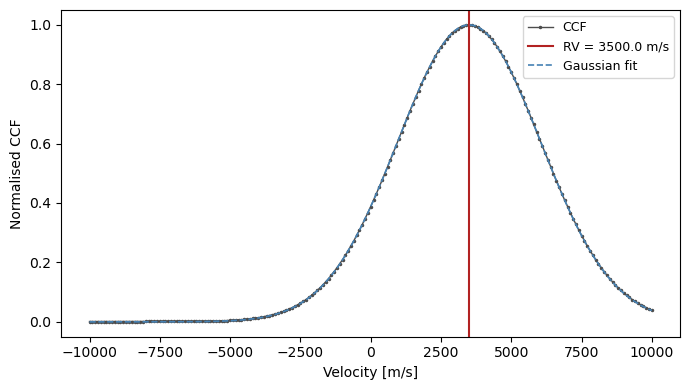

In [8]:
wave = np.linspace(5000e-10, 5010e-10, 4000)
line_wavs = np.linspace(5001e-10, 5009e-10, 12)

def absorption_spectrum(wave, centres, depth=0.4, width=0.03e-10):
    flux = np.ones_like(wave)
    for c in centres:
        flux -= depth * np.exp(-0.5 * ((wave - c) / width) ** 2)
    return flux

flux1 = absorption_spectrum(wave, line_wavs)

v_true = 3500.0  # m/s, injected shift
flux2 = absorption_spectrum(wave, line_wavs * (1.0 + v_true / C_LIGHT_MPS))

rv_result = psfcal.compute_rv_shift(
    wave, flux1, wave, flux2,
    velocity_range=(-10_000.0, 10_000.0),
    velocity_step=100.0,
    continuum_normalize=False,
)
print(f"recovered RV: {rv_result['rv']:.1f} +/- {rv_result['rv_err']:.1f} m/s   (true: {v_true} m/s)")

plotting.plot_ccf(rv_result)
plt.show()